# 16.14 - Explicit visual negative review

Select frontal source-train images from a low seam-score sample, inspect the originals, and record both target states separately. A low computer score never creates a negative label by itself. Ambiguous or partly hidden anterior alignment remains uncertain.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
root=Path.cwd().resolve()
while not (root / "AGENTS.md").exists():
    if root==root.parent: raise RuntimeError("Project root not found")
    root=root.parent
base=root / "data/processed/alignment_omni_frontal_candidates"
out=root / "docs/reports/alignment/agent_visual_pilot"
source=pd.read_csv(base / "review_queue.csv",dtype={"source_image_id":str,"sha256":str}).set_index("source_image_id")
excluded=set(pd.read_csv(root / "docs/reports/alignment/omni_frontal_candidate_audit/conservative_train_exclusions.csv",dtype=str).source_image_id)

## 1. Record reviewed states

No visible upper central gap in these five originals. Only two have sufficiently visible and orderly anterior teeth to mark crowding absent; the remaining three are uncertain for crowding. These are agent visual research labels.

In [2]:
reviews=pd.DataFrame([
    ("202401202403121","absent","absent","upper central contact; anterior teeth visible without obvious overlap"),
    ("202033202012241","absent","absent","upper central contact; anterior teeth visible without obvious overlap"),
    ("202243202302031","absent","uncertain","upper central contact; lower anterior overlap is ambiguous"),
    ("202322202302101","absent","uncertain","upper central contact; lower anterior overlap is ambiguous"),
    ("202346202310161","absent","uncertain","upper central contact; lower anterior teeth are obscured"),
],columns=["source_image_id","diastema_review","crowding_review","visual_reason"])
reviews["view_review"]="frontal"
reviews["reviewer"]="Codex visual review"
reviews["review_state"]="agent_visual_provisional"
for r in reviews.itertuples():
    s=source.loc[r.source_image_id]
    assert s["split"]=="train" and r.source_image_id not in excluded
    assert hashlib.sha256((root / s["image_path"]).read_bytes()).hexdigest()==s["sha256"]
display(reviews)

,source_image_id,diastema_review,crowding_review,visual_reason,view_review,reviewer,review_state
0,202401202403121,absent,absent,upper central contact; anterior teeth visible ...,frontal,Codex visual review,agent_visual_provisional
1,202033202012241,absent,absent,upper central contact; anterior teeth visible ...,frontal,Codex visual review,agent_visual_provisional
2,202243202302031,absent,uncertain,upper central contact; lower anterior overlap ...,frontal,Codex visual review,agent_visual_provisional
3,202322202302101,absent,uncertain,upper central contact; lower anterior overlap ...,frontal,Codex visual review,agent_visual_provisional
4,202346202310161,absent,uncertain,upper central contact; lower anterior teeth ar...,frontal,Codex visual review,agent_visual_provisional


## 2. Show the reviewed negatives

A negative image contributes an empty YOLO label only after both target statuses are explicitly absent. Images with an uncertain crowding status cannot become whole-image negatives.

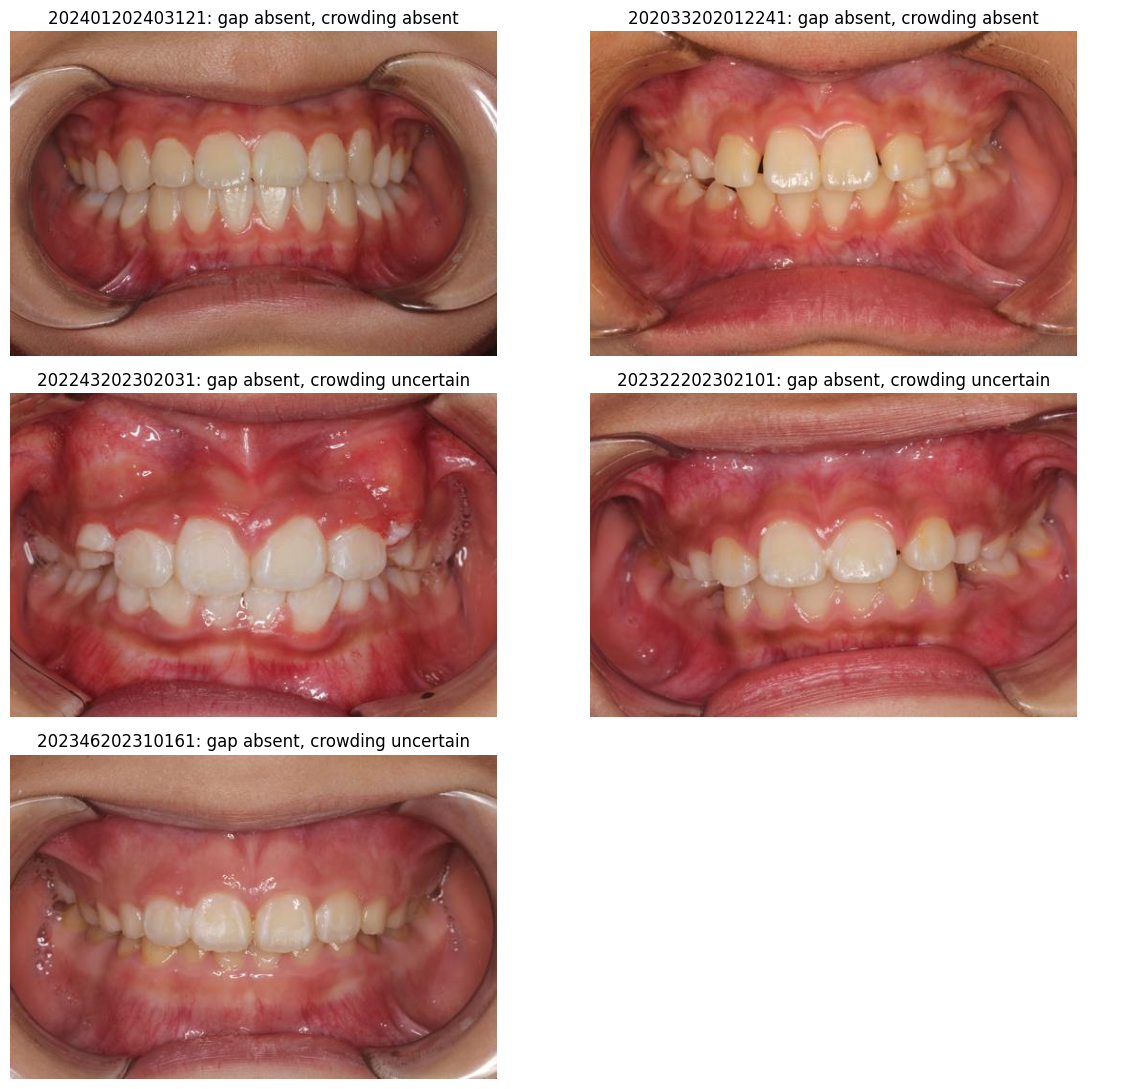

In [3]:
fig,axes=plt.subplots(3,2,figsize=(12,11))
for ax,r in zip(axes.flat,reviews.itertuples()):
    ax.imshow(Image.open(root / source.loc[r.source_image_id,"image_path"]))
    ax.set_title(f"{r.source_image_id}: gap {r.diastema_review}, crowding {r.crowding_review}")
    ax.axis("off")
for ax in list(axes.flat)[len(reviews):]: ax.axis("off")
fig.tight_layout()
fig.savefig(out / "negative_review_batch.png",dpi=150)
plt.show(); plt.close(fig)

## 3. Save visual review provenance

The output stays separate from OMNI source annotations. It must not be interpreted as dentist-reviewed ground truth or phone-photo specificity.

In [4]:
path=out / "negative_review_states.csv"
if path.exists(): assert pd.read_csv(path,dtype={"source_image_id":str}).equals(reviews),f"Existing review differs: {path}"
else: reviews.to_csv(path,index=False)
print("Saved",path)
print("Two-target visual negatives:",sum((reviews.diastema_review=="absent") & (reviews.crowding_review=="absent")))

Saved C:\Users\huynh\Desktop\oral-disease\docs\reports\alignment\agent_visual_pilot\negative_review_states.csv
Two-target visual negatives: 2
